# 02c Mediana de reseñas por género y por categoría

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md)

**Origen:** convertido del script `medianaResenasPorGenero.py`, que se eliminó de `borradores/` al pasar a este notebook.

## Objetivo

Comparar el volumen de reseñas entre géneros y categorías de Steam, controlando la exposición con los juegos que tienen al menos 3 años en tienda.

| Entradas | Salidas |
|---|---|
| `steam_games.csv.gz` (versión 2026-11-19) | `reports/figures/medianaResenasPorGenero.png`, `reports/metrics/medianaResenasPorGenero.csv`, `reports/metrics/medianaResenasPorCategoria.csv` |

## Configuración

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

import json
from collections import Counter
from matplotlib.ticker import FuncFormatter

minGroupSize = 300   # grupos con menos juegos no se grafican
maxCategories = 25   # categorías más frecuentes a mostrar
minAgeYears = 3      # filtro de exposición para el segundo marcador

Datos: steam_games.csv.gz


## Carga

In [2]:
gamesDf = pd.read_csv(dataPath, usecols=['app_id', 'release_date', 'positive', 'negative', 'genres', 'categories'],
                      low_memory=False)
gamesDf['reviewCount'] = (pd.to_numeric(gamesDf['positive'], errors='coerce')
                          + pd.to_numeric(gamesDf['negative'], errors='coerce'))
releaseDate = pd.to_datetime(gamesDf['release_date'], errors='coerce', format='mixed')
gamesDf['ageYears'] = (snapshotDate - releaseDate).dt.days / 365.25
print(f'{len(gamesDf):,} juegos')

150,199 juegos


## Etiquetas multivalor

`genres` y `categories` vienen en dos formatos (listas de texto y listas de objetos con `id` y `description`). Se unifican por `id` y se usa la descripción más frecuente como nombre canónico, porque algunas filas están traducidas. Un juego cuenta en cada etiqueta que tenga.

In [3]:
def parseLabels(rawValue):
    """Devuelve una lista de pares (id, descripción) a partir de JSON con objetos o con textos."""
    if not isinstance(rawValue, str) or not rawValue.strip():
        return []
    try:
        parsedList = json.loads(rawValue)
    except json.JSONDecodeError:
        return []
    labelPairs = []
    for item in parsedList:
        if isinstance(item, dict):
            labelPairs.append((str(item.get('id', item.get('description'))), str(item.get('description', '')).strip()))
        elif isinstance(item, str):
            labelPairs.append((item.strip(), item.strip()))
    return labelPairs


def groupStats(columnName):
    """Explota la columna multietiqueta y calcula estadísticos de reseñas por etiqueta."""
    pairSeries = gamesDf[columnName].map(parseLabels)
    # nombre canónico por id: la descripción más frecuente (algunas filas vienen localizadas)
    nameCounter = {}
    for pairList in pairSeries:
        for labelId, labelName in pairList:
            nameCounter.setdefault(labelId, Counter())[labelName] += 1
    canonicalName = {labelId: counter.most_common(1)[0][0] for labelId, counter in nameCounter.items()}

    longDf = pd.DataFrame({
        'app_id': gamesDf['app_id'].repeat(pairSeries.map(len)).values,
        'labelId': [labelId for pairList in pairSeries for labelId, _ in pairList],
    }).drop_duplicates()
    longDf['label'] = longDf['labelId'].map(canonicalName)
    longDf = longDf.merge(gamesDf[['app_id', 'reviewCount', 'ageYears']], on='app_id').dropna(subset=['reviewCount'])

    allStats = longDf.groupby('label')['reviewCount'].agg(
        n='size', median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    matureStats = longDf[longDf['ageYears'] >= minAgeYears].groupby('label')['reviewCount'].agg(
        nMature='size', medianMature='median',
        q25Mature=lambda s: s.quantile(0.25), q75Mature=lambda s: s.quantile(0.75))
    statsDf = allStats.join(matureStats).reset_index()
    statsDf = statsDf[(statsDf['n'] >= minGroupSize) & (statsDf['nMature'] >= minGroupSize)]
    statsDf['pctRecent'] = 100 * (1 - statsDf['nMature'] / statsDf['n'])
    return statsDf


genreStats = groupStats('genres')
categoryStats = groupStats('categories').nlargest(maxCategories, 'n')
genreStats.to_csv(metricsDir / 'medianaResenasPorGenero.csv', index=False)
categoryStats.to_csv(metricsDir / 'medianaResenasPorCategoria.csv', index=False)

overallMedian = gamesDf['reviewCount'].median()
overallMatureMedian = gamesDf.loc[gamesDf['ageYears'] >= minAgeYears, 'reviewCount'].median()
print('Mediana global:', overallMedian, '| mediana global con ≥', minAgeYears, 'años:', overallMatureMedian)

Mediana global: 2.0 | mediana global con ≥ 3 años: 18.0


### Géneros

In [4]:
genreStats.sort_values('medianMature', ascending=False).round(1)

,label,n,median,q25,q75,nMature,medianMature,q25Mature,q75Mature,pctRecent
20,Massively Multiplayer,3059,5.0,0.0,108.5,1694.0,44.0,5.0,488.0,44.6
25,RPG,25622,4.0,0.0,61.0,12834.0,28.0,5.0,217.0,49.9
30,Simulation,31645,2.0,0.0,41.0,14466.0,27.0,5.0,159.0,54.3
34,Strategy,29337,3.0,0.0,38.0,13987.0,25.0,5.0,154.5,52.3
3,Adventure,53611,6.0,0.0,48.0,28843.0,24.0,5.0,136.0,46.2
4,Animation & Modeling,484,14.5,1.0,59.0,358.0,23.0,7.0,94.5,26.0
39,Violent,406,22.0,7.0,67.8,406.0,22.0,7.0,67.8,0.0
9,Design & Illustration,585,16.0,3.0,62.0,449.0,22.0,7.0,92.0,23.2
14,Free To Play,15370,0.0,0.0,16.0,6287.0,22.0,0.0,171.0,59.1
2,Action,55388,5.0,0.0,41.2,30425.0,21.0,4.0,121.0,45.1


### Categorías (25 más frecuentes)

In [5]:
categoryStats.sort_values('medianMature', ascending=False).round(1)

,label,n,median,q25,q75,nMature,medianMature,q25Mature,q75Mature,pctRecent
26,DualSense Controller Support,6172,0.0,0.0,0.0,1244.0,883.5,78.8,7618.0,79.8
27,DualShock Controller Support,6525,0.0,0.0,19.0,1532.0,878.0,86.0,7244.0,76.5
4,Adjustable Difficulty,6381,0.0,0.0,0.0,721.0,477.0,42.0,4653.0,88.7
77,Steam Trading Cards,11654,295.0,72.0,1393.8,10340.0,324.0,88.0,1495.2,11.3
23,Custom Volume Controls,18234,0.0,0.0,0.0,1329.0,286.0,30.0,2986.0,92.7
6,Camera Comfort,6895,0.0,0.0,0.0,835.0,257.0,23.5,3554.0,87.9
63,Save Anytime,10424,0.0,0.0,0.0,799.0,238.0,26.5,2371.0,92.3
81,Stereo Sound,9935,0.0,0.0,0.0,964.0,227.0,23.0,4909.2,90.3
55,Playable without Timed Input,19141,0.0,0.0,0.0,1377.0,126.0,17.0,1592.0,92.8
73,Steam Cloud,41033,7.0,0.0,124.0,18475.0,83.0,15.0,582.0,55.0


## Gráfica

Las barras muestran la mediana de los juegos con al menos 3 años; los rombos, la mediana de todos los juegos. Steam Trading Cards se marca en rojo (†) porque Steam la habilita después del lanzamiento según ventas y actividad, así que no es un predictor válido.

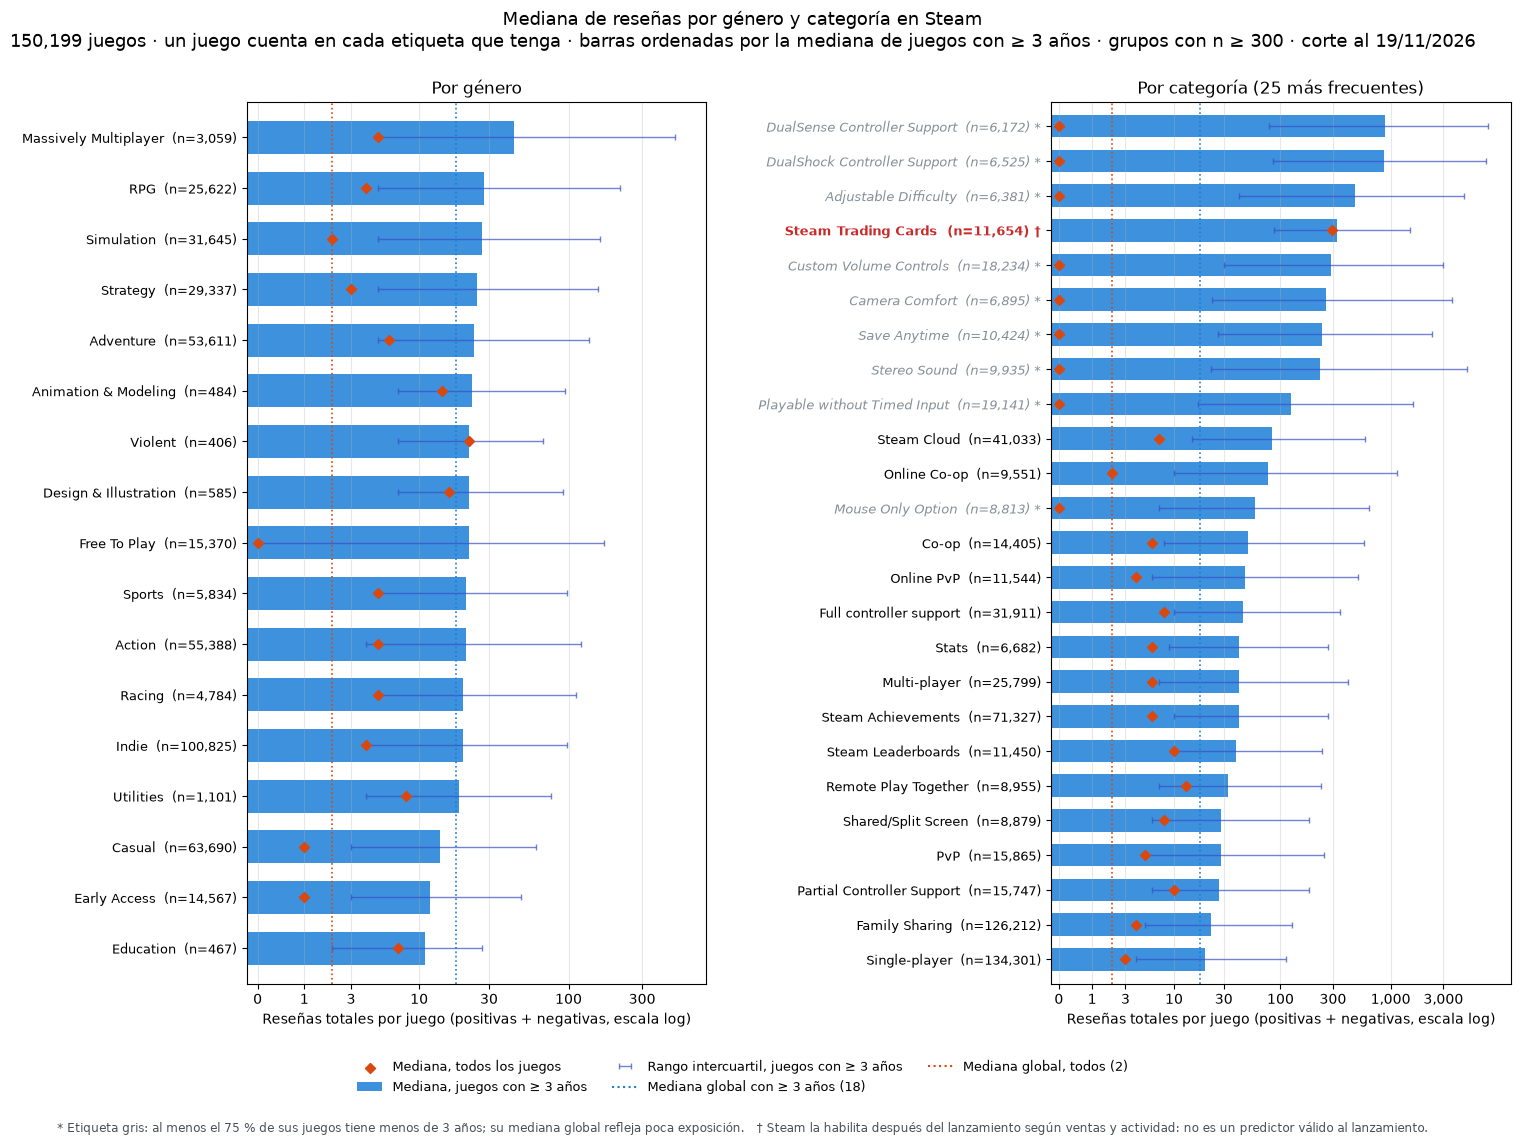

In [6]:
symlogShift = 1  # se grafica valor + 1 en escala log para admitir medianas de 0
recentShareFlag = 75  # % de juegos con < minAgeYears años a partir del cual se marca la etiqueta
postLaunchLabels = {'Steam Trading Cards'}  # Steam la habilita después del lanzamiento según ventas y actividad
tickValues = [0, 1, 3, 10, 30, 100, 300, 1000, 3000]


def suffixFor(name, pctRecent):
    return ' †' if name in postLaunchLabels else (' *' if pctRecent >= recentShareFlag else '')


def drawPanel(ax, statsDf, panelTitle):
    statsDf = statsDf.sort_values(['medianMature', 'median'], ascending=True).reset_index(drop=True)
    yPos = np.arange(len(statsDf))
    ax.barh(yPos, statsDf['medianMature'] + symlogShift, color='#1C7ED6', alpha=0.85, height=0.65,
            label=f'Mediana, juegos con ≥ {minAgeYears} años')
    ax.errorbar(statsDf['medianMature'] + symlogShift, yPos,
                xerr=[statsDf['medianMature'] - statsDf['q25Mature'], statsDf['q75Mature'] - statsDf['medianMature']],
                fmt='none', ecolor='#364FC7', elinewidth=1, capsize=2.5, alpha=0.7,
                label=f'Rango intercuartil, juegos con ≥ {minAgeYears} años')
    ax.scatter(statsDf['median'] + symlogShift, yPos, marker='D', s=26, color='#D9480F', zorder=3,
               label='Mediana, todos los juegos')
    ax.axvline(overallMatureMedian + symlogShift, color='#1C7ED6', ls=':', lw=1.2)
    ax.axvline(overallMedian + symlogShift, color='#D9480F', ls=':', lw=1.2)
    ax.set_yticks(yPos)
    ax.set_yticklabels([f'{name}  (n={n:,}){suffixFor(name, p)}'
                        for name, n, p in zip(statsDf['label'], statsDf['n'], statsDf['pctRecent'])], fontsize=9)
    for tickLabel, name, pctRecent in zip(ax.get_yticklabels(), statsDf['label'], statsDf['pctRecent']):
        if name in postLaunchLabels:
            tickLabel.set_color('#C92A2A')
            tickLabel.set_fontweight('bold')
        elif pctRecent >= recentShareFlag:
            tickLabel.set_color('#868E96')
            tickLabel.set_fontstyle('italic')
    ax.set_xscale('log')
    xMax = max(statsDf['q75Mature'].max(), statsDf['median'].max()) * 1.6
    ax.set_xlim(0.85, xMax)
    visibleTicks = [v for v in tickValues if v + symlogShift <= xMax]
    ax.set_xticks([v + symlogShift for v in visibleTicks])
    ax.set_xticklabels([f'{v:,}' for v in visibleTicks])
    ax.minorticks_off()
    ax.set_xlabel('Reseñas totales por juego (positivas + negativas, escala log)')
    ax.set_title(panelTitle, fontsize=12)
    ax.grid(axis='x', alpha=0.3)
    ax.set_ylim(-0.7, len(statsDf) - 0.3)


genreHeight = len(genreStats)
categoryHeight = len(categoryStats)
fig, (axGenre, axCategory) = plt.subplots(1, 2, figsize=(16, 0.36 * max(genreHeight, categoryHeight) + 2.6),
                                          gridspec_kw={'wspace': 0.75})
drawPanel(axGenre, genreStats, 'Por género')
drawPanel(axCategory, categoryStats, f'Por categoría ({maxCategories} más frecuentes)')
handles, labels = axGenre.get_legend_handles_labels()
handles += [plt.Line2D([], [], color='#1C7ED6', ls=':'), plt.Line2D([], [], color='#D9480F', ls=':')]
labels += [f'Mediana global con ≥ {minAgeYears} años ({overallMatureMedian:,.0f})',
           f'Mediana global, todos ({overallMedian:,.0f})']
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.035))
fig.text(0.5, 0.012,
         f'* Etiqueta gris: al menos el {recentShareFlag} % de sus juegos tiene menos de {minAgeYears} años; '
         'su mediana global refleja poca exposición.   '
         '† Steam la habilita después del lanzamiento según ventas y actividad: no es un predictor válido al lanzamiento.',
         ha='center', fontsize=8.5, color='#495057')
fig.suptitle(f'Mediana de reseñas por género y categoría en Steam\n'
             f"{gamesDf['reviewCount'].notna().sum():,} juegos · un juego cuenta en cada etiqueta que tenga · "
             f'barras ordenadas por la mediana de juegos con ≥ {minAgeYears} años · grupos con n ≥ {minGroupSize} · '
             f"corte al {snapshotDate.strftime('%d/%m/%Y')}", fontsize=13)
fig.subplots_adjust(left=0.19, right=0.98, top=0.9, bottom=0.14)
fig.savefig(figuresDir / 'medianaResenasPorGenero.png', dpi=160)
plt.show()

## Conclusiones del notebook

- La antigüedad pesa más que cualquier etiqueta: la mediana global es de 2 reseñas con todos los juegos y de 18 con los que tienen al menos 3 años.
- Entre los juegos con al menos 3 años, las diferencias por género son moderadas. Massively Multiplayer tiene la mediana más alta (44), seguido de RPG (28) y Simulation (27); Casual (14), Early Access (12) y Education (11) quedan al final.
- Las categorías de multijugador y de servicios de Steam (Steam Cloud, Co-op, Online PvP) superan a Single-player y Family Sharing, que casi todos los juegos tienen.
- Steam Trading Cards tiene la mediana más alta, pero es consecuencia del éxito y no causa: se descarta como predictor.
- Indie, Early Access y Free To Play son etiquetas comerciales, no géneros; se separan de los géneros (decisión D-005). Los géneros de software (Utilities, Design & Illustration, Animation & Modeling, Education…) identifican filas que no son juegos.